Mutivariate Analysis


In [2]:
import pandas as pd
import numpy as np
!pip install seaborn
import seaborn as sns
import matplotlib.pyplot as plt

Loading Datasets

In [3]:
titanic = pd.read_csv("https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv")
tips = sns.load_dataset("tips")
flights = sns.load_dataset("flights")
iris = sns.load_dataset("iris")


1. Scatterplot => Numerical to Numerical

In [7]:
tips.sample(5)

,total_bill,tip,sex,smoker,day,time,size
140,17.47,3.50,Female,No,Thur,Lunch,2
23,39.42,7.58,Male,No,Sat,Dinner,4
149,7.51,2.00,Male,No,Thur,Lunch,2
46,22.23,5.00,Male,No,Sun,Dinner,2
160,21.50,3.50,Male,No,Sun,Dinner,4


<Axes: xlabel='total_bill', ylabel='tip'>

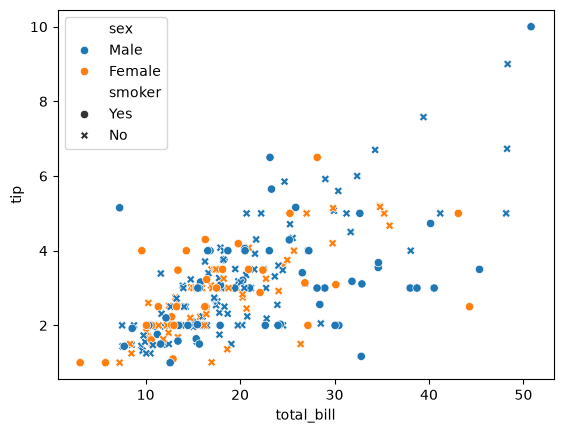

In [11]:
sns.scatterplot(data=tips, x="total_bill", y="tip",hue='sex',style='smoker')

2. Barplot => Numerical to Categorical

In [12]:
titanic.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
669,670,1,1,"Taylor, Mrs. Elmer Zebley (Juliet Cummins Wright)",female,NaN,1,0,19996,52.0000,C126,S
272,273,1,2,"Mellinger, Mrs. (Elizabeth Anne Maidment)",female,41.0,0,1,250644,19.5000,NaN,S
490,491,0,3,"Hagland, Mr. Konrad Mathias Reiersen",male,NaN,1,0,65304,19.9667,NaN,S
578,579,0,3,"Caram, Mrs. Joseph (Maria Elias)",female,NaN,1,0,2689,14.4583,NaN,C
820,821,1,1,"Hays, Mrs. Charles Melville (Clara Jennings Gr...",female,52.0,1,1,12749,93.5000,B69,S


<Axes: xlabel='Sex', ylabel='Age'>

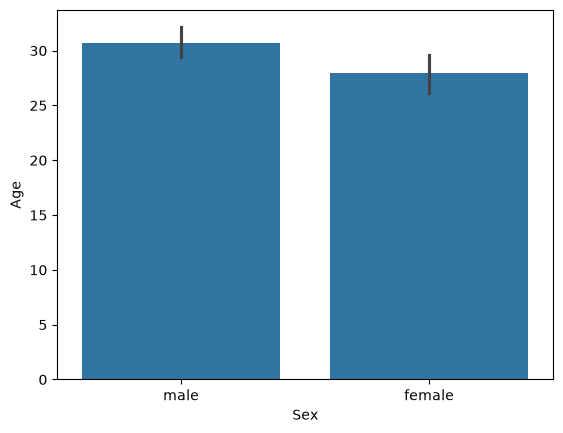

In [14]:
sns.barplot(data=titanic, x="Sex", y="Age")

3. Boxplot => Numerical to Catergorical

<Axes: xlabel='Sex', ylabel='Age'>

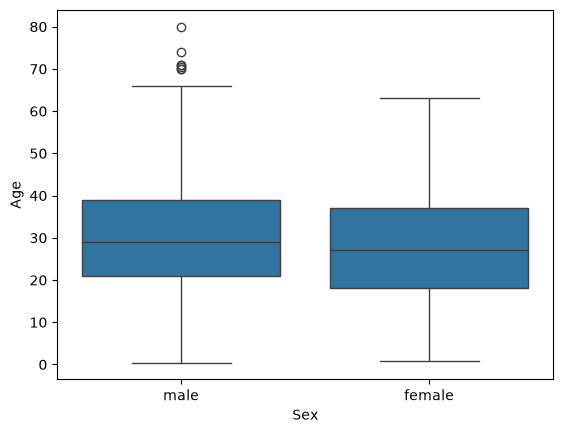

In [20]:
sns.boxplot(x='Sex', y='Age', data=titanic)

<Axes: xlabel='Sex', ylabel='Age'>

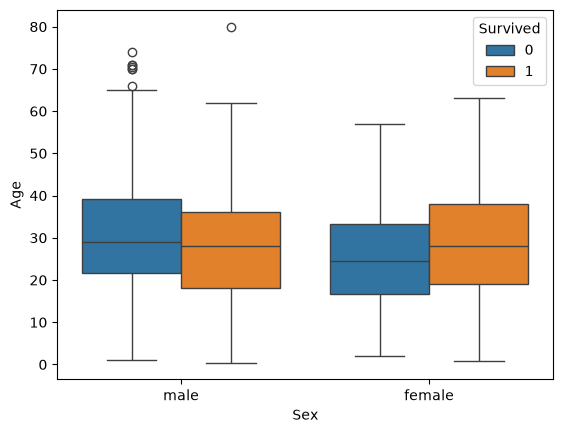

In [22]:
sns.boxplot(x='Sex', y='Age', data=titanic,hue='Survived')

4. Distplot => Numerocal to Categorical

C:\Users\91630\AppData\Local\Temp\ipykernel_29952\1704664756.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(titanic[titanic['Survived']==0]['Age'],hist=False,label='Not Survived')
C:\Users\91630\AppData\Local\Temp\ipykernel_29952\1704664756.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5

<Axes: xlabel='Age', ylabel='Density'>

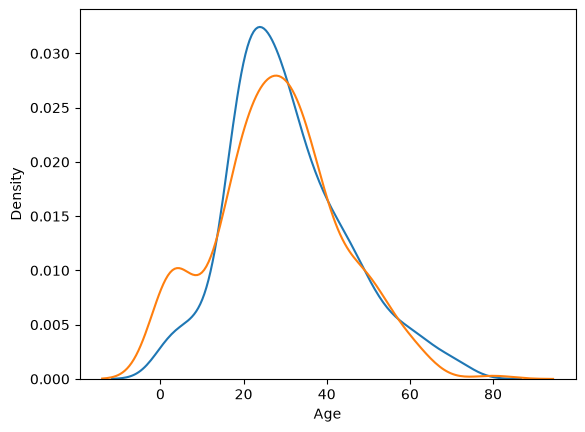

In [25]:
sns.distplot(titanic[titanic['Survived']==0]['Age'],hist=False,label='Not Survived')
sns.distplot(titanic[titanic['Survived']==1]['Age'],hist=False,label='Survived')

5. Heatmap => Categorical to Categorical

In [28]:
pd.crosstab(titanic['Pclass'],titanic['Survived'],margins=True)

Survived,0,1,All
Pclass,,,
1,80,136,216
2,97,87,184
3,372,119,491
All,549,342,891


<Axes: xlabel='Survived', ylabel='Pclass'>

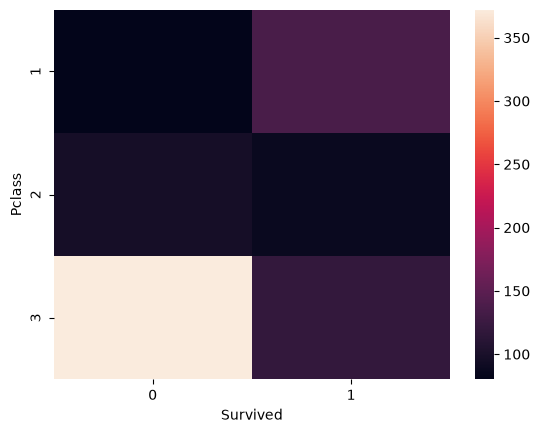

In [30]:
sns.heatmap(pd.crosstab(titanic['Pclass'],titanic['Survived']))

In [33]:
titanic.groupby(['Pclass'])['Survived'].mean()*100

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

<Axes: xlabel='Pclass'>

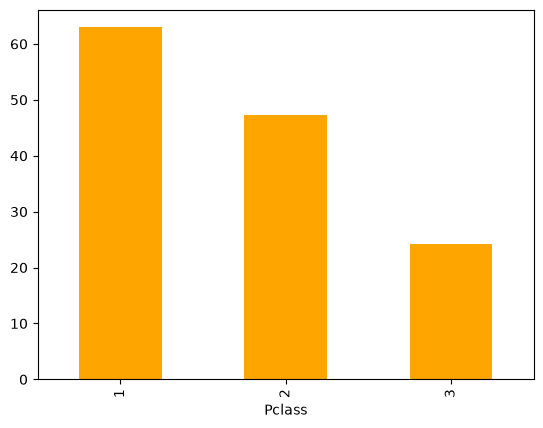

In [34]:
(titanic.groupby(['Pclass'])['Survived'].mean()*100).plot(kind='bar',color='orange')

6. ClusterMap => Categorical to Categorical => It will draw dendogram and will cluster simailr data together

In [35]:
titanic.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
567,568,0,3,"Palsson, Mrs. Nils (Alma Cornelia Berglund)",female,29.0,0,4,349909,21.075,NaN,S
705,706,0,2,"Morley, Mr. Henry Samuel (""Mr Henry Marshall"")",male,39.0,0,0,250655,26.000,NaN,S
104,105,0,3,"Gustafsson, Mr. Anders Vilhelm",male,37.0,2,0,3101276,7.925,NaN,S
228,229,0,2,"Fahlstrom, Mr. Arne Jonas",male,18.0,0,0,236171,13.000,NaN,S
144,145,0,2,"Andrew, Mr. Edgardo Samuel",male,18.0,0,0,231945,11.500,NaN,S


In [36]:
pd.crosstab(titanic["SibSp"],titanic["Survived"],margins=True)

Survived,0,1,All
SibSp,,,
0,398,210,608
1,97,112,209
2,15,13,28
3,12,4,16
4,15,3,18
5,5,0,5
8,7,0,7
All,549,342,891


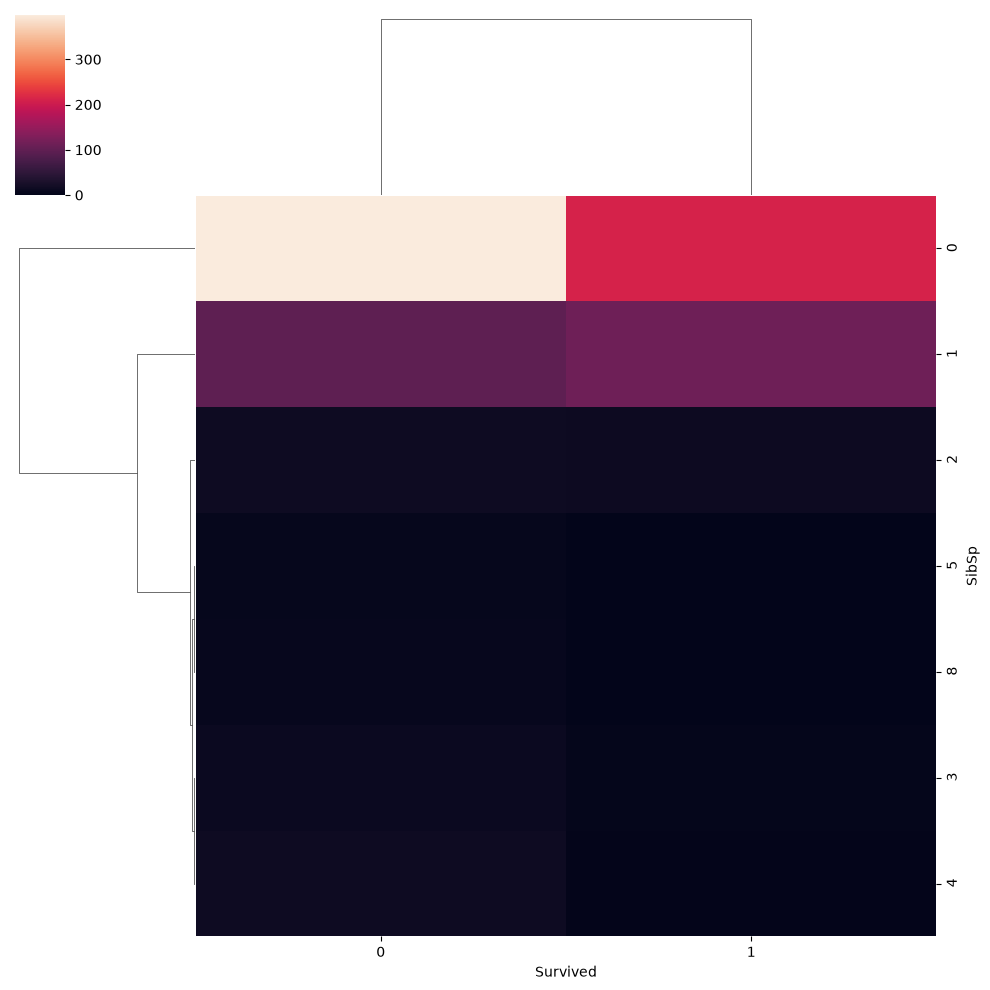

In [45]:
sns.clustermap(pd.crosstab(titanic["SibSp"],titanic["Survived"]))

7. Pairplot

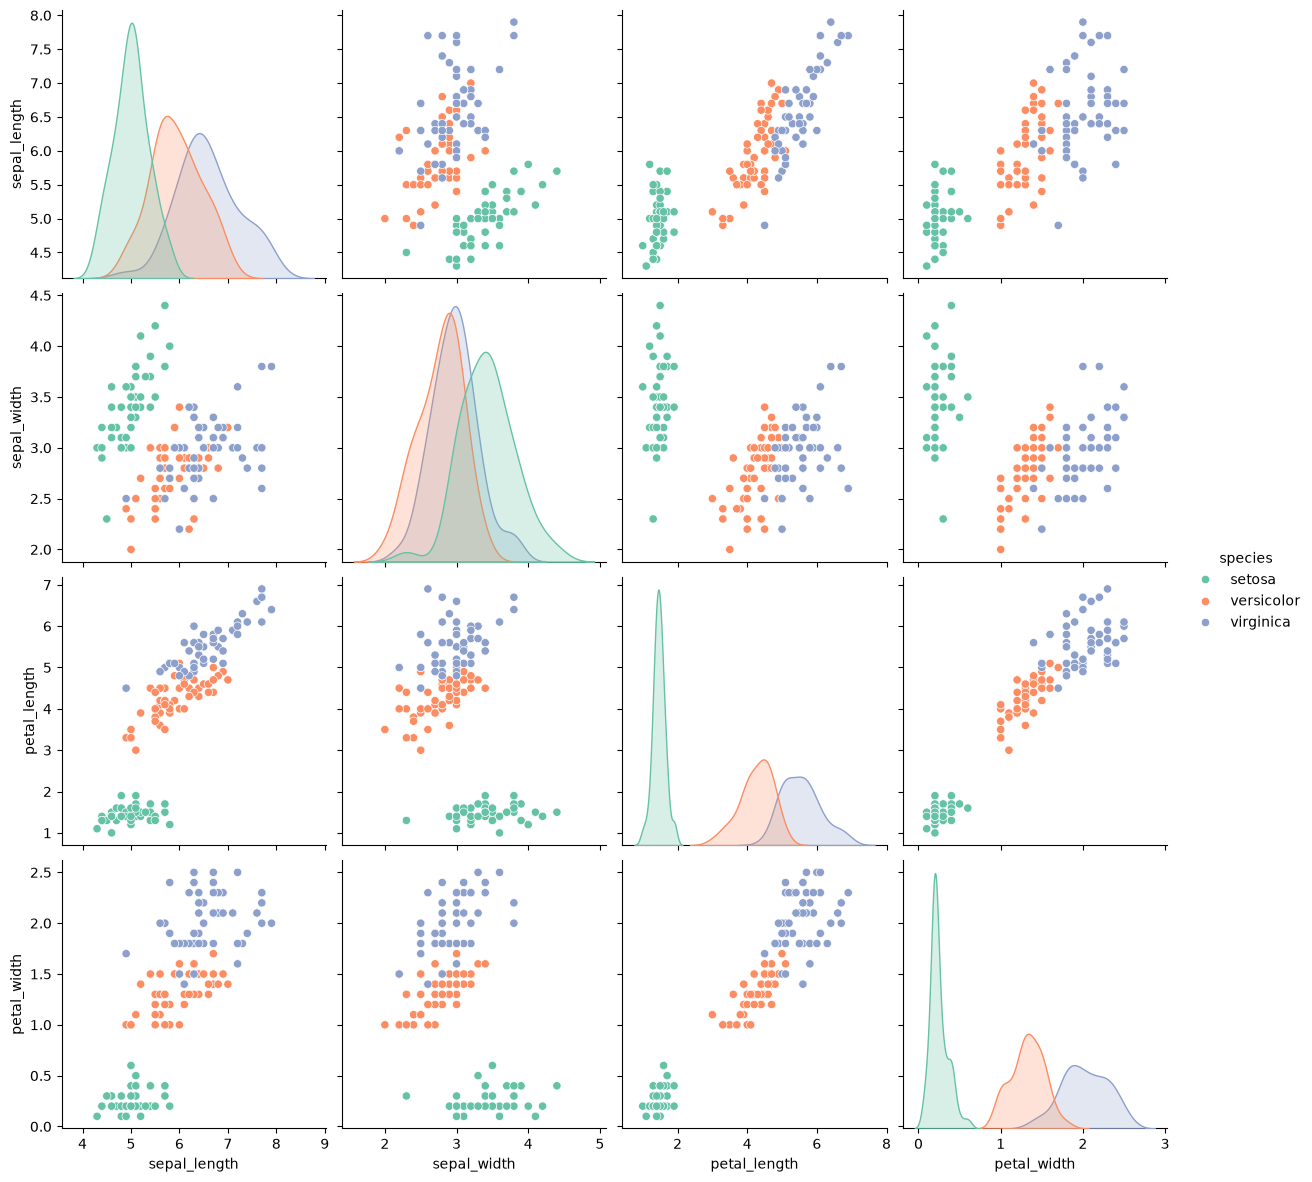

In [37]:
sns.pairplot(iris, hue='species', palette='Set2', height=3)

8. Lineplot => Numerical to Numerical => Use when the pne column is time based

In [46]:
flights_pivot = flights.pivot_table(index='month', columns='year', values='passengers')

<Axes: xlabel='year'>

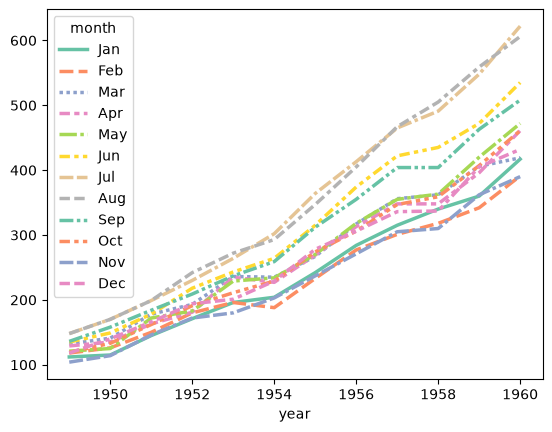

In [47]:
sns.lineplot(data=flights_pivot.T, palette='Set2', linewidth=2.5)

<Axes: xlabel='year', ylabel='month'>

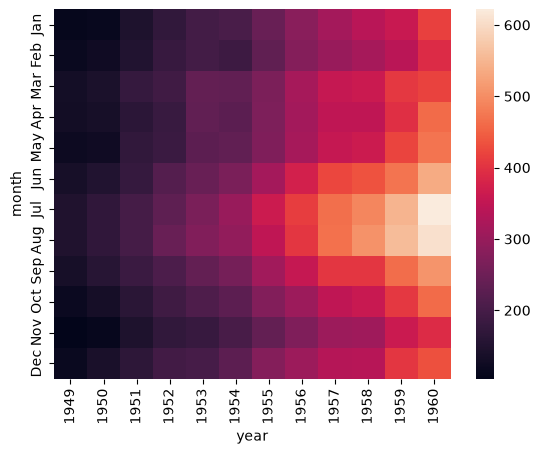

In [49]:
sns.heatmap(flights.pivot_table(index='month', columns='year', values='passengers'))